# Multi-agent order picking in a warehouse

# Warehouse grid

Symbols in the map:
* `.` floor
* `#` shelf
* `S` start
* `G` goal

Coordinates are (row, col), with (0, 0) in the top left corner.

In [28]:
from collections import deque

import numpy as np

In [29]:
def make_layout(
    n_shelf_rows=2,
    shelves_per_row=3,
    shelf_width=2,
    shelf_depth=2,
):
    # one aisle more than the number of shelves, in both directions
    n_rows = n_shelf_rows * shelf_depth + (n_shelf_rows + 1)
    n_cols = shelves_per_row * shelf_width + (shelves_per_row + 1)

    # start with floor everywhere
    grid = np.full((n_rows, n_cols), ".")

    # place the shelves
    for i in range(n_shelf_rows):
        for j in range(shelves_per_row):
            top = 1 + i * (shelf_depth + 1)
            left = 1 + j * (shelf_width + 1)
            grid[top:top + shelf_depth, left:left + shelf_width] = "#"

    # start top left, goal bottom right
    grid[0, 0] = "S"
    grid[-1, -1] = "G"

    return "\n".join("".join(row) for row in grid)

In [30]:
class WarehouseGrid:
    def __init__(self, layout=None):
        # default map if none is given
        if layout is None:
            layout = make_layout()

        rows = layout.strip().splitlines()
        self.n_rows = len(rows)
        self.n_cols = len(rows[0])

        # which symbol is in each cell
        symbols = {(r, c): symbol
                   for r, row in enumerate(rows)
                   for c, symbol in enumerate(row)}

        # sort the cells by symbol
        self.shelf_cells = {cell for cell, s in symbols.items() if s == "#"}
        self.walkable_cells = {cell for cell, s in symbols.items() if s != "#"}
        self.start = next((cell for cell, s in symbols.items() if s == "S"), None)
        self.goal = next((cell for cell, s in symbols.items() if s == "G"), None)

        # pick spots: the floor cells next to each shelf cell
        self.pick_spots = {
            shelf: self.walkable_neighbors(shelf) for shelf in self.shelf_cells
        }

        # which item lies on which shelf
        self.item_to_shelf = {}

        self.check_all_cells_reachable()

    # the floor cells above, below, left and right
    def walkable_neighbors(self, cell):
        r, c = cell
        around = [(r - 1, c), (r + 1, c), (r, c - 1), (r, c + 1)]
        return [n for n in around if n in self.walkable_cells]

    # raise an error if the map is split in parts or a shelf cannot be reached
    def check_all_cells_reachable(self):
        start = next(iter(self.walkable_cells))
        visited = {start}
        queue = deque([start])
        while queue:
            for n in self.walkable_neighbors(queue.popleft()):
                if n not in visited:
                    visited.add(n)
                    queue.append(n)

        # cells that were never reached mean the map is split
        if visited != self.walkable_cells:
            raise ValueError(f"Unreachable floor cells: {sorted(self.walkable_cells - visited)}")

        # every shelf needs at least one pick spot
        for shelf, spots in self.pick_spots.items():
            if not spots:
                raise ValueError(f"Shelf {shelf} has no pick spot.")

    # put an item on a shelf
    def add_item(self, item, shelf):
        if shelf not in self.shelf_cells:
            raise ValueError(f"{shelf} is not a shelf!")
        self.item_to_shelf[item] = shelf

    # put each item on a random shelf, at most one item per shelf
    def place_items_randomly(self, items, seed=None):
        rng = np.random.default_rng(seed)
        shelves = sorted(self.shelf_cells)
        chosen = rng.choice(len(shelves), size=len(items), replace=False)
        for item, i in zip(items, chosen):
            self.add_item(item, shelves[i])

    # where to stand to pick an item
    def pick_spots_for_item(self, item):
        return self.pick_spots[self.item_to_shelf[item]]

    # draw the map, layer by layer
    def render(self, show_pick_spots=False):
        grid = np.full((self.n_rows, self.n_cols), ".")

        if show_pick_spots:
            for spots in self.pick_spots.values():
                for cell in spots:
                    grid[cell] = "p"

        for cell in self.shelf_cells:
            grid[cell] = "#"

        if self.start is not None:
            grid[self.start] = "S"
        if self.goal is not None:
            grid[self.goal] = "G"

        for row in grid:
            print(" ".join(row))
        print()

## Step 1 and 2: two agents that can collide

* Each agent has its own start and its own goal.
* `WAIT` = stand still, so that one agent can let the other pass.
* The state is both agents' positions: `((row, col), (row, col))`.

Rules in `step()`:
1. Shelf or outside the map -> the agent stays where it is.
2. Both want the same cell -> both stay.
3. They try to swap places -> both stay.

Every step gives `-1`. The agent that is blocked by the other one gets `-5` extra. An agent at its goal stands still.

Two ways to give the step reward (`reward_mode`):
* `"selfish"` (default): an agent at its goal gets `0`. Each agent only cares about its own time.
* `"cooperative"`: an agent at its goal gets `-1` per step until *both* are at their goals. The fast agent pays for the slow one not being done, so it pays off to let the other one pass.

In [31]:
STEP_REWARD = -1    # every step costs, so the agents want to finish fast
CRASH_REWARD = -5   # extra penalty for trying to walk into the other agent

# how each action moves an agent (row, col)
ACTIONS = {
    "UP": (-1, 0),
    "DOWN": (1, 0),
    "LEFT": (0, -1),
    "RIGHT": (0, 1),
    "WAIT": (0, 0),
}


class TwoAgentWarehouse:
    def __init__(self, grid, starts, goals, reward_mode="selfish"):
        self.grid = grid        # WarehouseGrid, shelves and floor
        self.starts = starts    # one start per agent, e.g. [(0, 0), (0, 9)]
        self.goals = goals      # one goal per agent
        # "selfish": 0 once you are at your goal. "cooperative": -1 until both are at their goals
        if reward_mode not in ("selfish", "cooperative"):
            raise ValueError(f"Unknown reward_mode: {reward_mode}")
        self.reward_mode = reward_mode
        self.reset()

    # put both agents back on their start
    def reset(self):
        self.positions = list(self.starts)
        return tuple(self.positions)

    # draw the map with agents A and B, and their goals a and b
    def render(self):
        grid = np.full((self.grid.n_rows, self.grid.n_cols), ".")

        for cell in self.grid.shelf_cells:
            grid[cell] = "#"

        for goal, name in zip(self.goals, "ab"):
            grid[goal] = name
        for pos, name in zip(self.positions, "AB"):
            grid[pos] = name

        for row in grid:
            print(" ".join(row))
        print()

    # move an agent one step, stay if it is a shelf or outside the map
    def move(self, pos, action):
        dr, dc = ACTIONS[action]
        new = (pos[0] + dr, pos[1] + dc)
        if new in self.grid.walkable_cells:
            return new
        return pos

    # both agents act at the same time, e.g. actions = ("RIGHT", "WAIT")
    def step(self, actions):
        old = list(self.positions)

        # where do the agents want to go? an agent already at its goal stands still
        wanted = []
        for i in range(2):
            if old[i] == self.goals[i]:
                wanted.append(old[i])
            else:
                wanted.append(self.move(old[i], actions[i]))

        # same cell or swapping places -> both stay
        same_cell = wanted[0] == wanted[1]
        swap = wanted[0] == old[1] and wanted[1] == old[0]
        if same_cell or swap:
            new = old
        else:
            new = wanted

        done = all(p == g for p, g in zip(new, self.goals))

        # rewards, one per agent
        rewards = []
        for i in range(2):
            if old[i] == self.goals[i]:
                if self.reward_mode == "selfish" or done:
                    rewards.append(0)  # already done, no more penalty
                else:
                    rewards.append(STEP_REWARD)  # done, but waiting for the other one
                continue
            reward = STEP_REWARD
            # wanted to move but was blocked by the other agent
            if wanted[i] != old[i] and new[i] == old[i]:
                reward += CRASH_REWARD
            rewards.append(reward)

        self.positions = list(new)
        return tuple(self.positions), rewards, done


In [32]:
env = TwoAgentWarehouse(
    WarehouseGrid(),
    starts=[(0, 0), (0, 9)],
    goals=[(6, 9), (6, 0)],
)
print(env.reset())
env.render()


((0, 0), (0, 9))
A . . . . . . . . B
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a



### Test of the collision rules

In [33]:
# a narrow corridor, so we can force collisions
env = TwoAgentWarehouse(
    WarehouseGrid("....."),
    starts=[(0, 0), (0, 4)],
    goals=[(0, 4), (0, 0)],
)
env.render()

tests = [
    (("RIGHT", "LEFT"), "both take one step"),
    (("RIGHT", "LEFT"), "both want the middle cell -> collision"),
    (("RIGHT", "WAIT"), "B waits, A moves to the middle"),
    (("RIGHT", "LEFT"), "they try to swap places -> collision"),
    (("UP", "WAIT"), "A walks into the wall, stays but no collision"),
]
for actions, text in tests:
    state, rewards, done = env.step(actions)
    print(f"{actions}: {text}")
    print(f"rewards = {rewards}")
    env.render()


A . . . B

('RIGHT', 'LEFT'): both take one step
rewards = [-1, -1]
b A . B a

('RIGHT', 'LEFT'): both want the middle cell -> collision
rewards = [-6, -6]
b A . B a

('RIGHT', 'WAIT'): B waits, A moves to the middle
rewards = [-1, -1]
b . A B a

('RIGHT', 'LEFT'): they try to swap places -> collision
rewards = [-6, -6]
b . A B a

('UP', 'WAIT'): A walks into the wall, stays but no collision
rewards = [-1, -1]
b . A B a



## Step 3: the agents learn with Q-learning

* Each agent has its own Q-table (independent Q-learning).
* The state is both positions, so each agent knows where the other one is.
* Epsilon-greedy: usually the best action, sometimes a random one to explore.
* Update: `Q[s][a] += alpha * (r + gamma * max Q[s'] - Q[s][a])`
* An agent that is already at its goal keeps learning, even though it cannot move. In `cooperative` mode it still gets a penalty, and that has to show up in the Q-values of the steps before. In `selfish` mode the reward at the goal is 0, so nothing changes there.

In [34]:
from collections import defaultdict

ACTION_NAMES = list(ACTIONS)  # ["UP", "DOWN", "LEFT", "RIGHT", "WAIT"]


# choose an action: usually the best one, sometimes a random one (epsilon-greedy)
def choose_action(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return rng.integers(len(ACTION_NAMES))
    q = Q[state]
    best = np.flatnonzero(q == q.max())  # if several are equally good, pick one at random
    return rng.choice(best)


# each agent has its own Q-table, but sees both positions
def train(env, episodes=10000, alpha=0.5, gamma=0.99, epsilon=0.1, max_steps=200, seed=0):
    rng = np.random.default_rng(seed)
    Qs = [defaultdict(lambda: np.zeros(len(ACTION_NAMES))) for _ in range(2)]
    steps_per_episode = []

    for episode in range(episodes):
        state = env.reset()
        for t in range(max_steps):
            a = [choose_action(Qs[i], state, epsilon, rng) for i in range(2)]
            next_state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))

            for i in range(2):
                if done:
                    target = rewards[i]  # episode over, no future left
                else:
                    target = rewards[i] + gamma * Qs[i][next_state].max()
                Qs[i][state][a[i]] += alpha * (target - Qs[i][state][a[i]])

            state = next_state
            if done:
                break
        steps_per_episode.append(t + 1)

    return Qs, steps_per_episode


In [35]:
# run one episode without randomness and show what the agents have learned
def run_greedy(env, Qs, max_steps=50, show=True):
    rng = np.random.default_rng(0)
    state = env.reset()
    finished = [None, None]  # the step at which each agent reached its goal
    crashes = 0
    if show:
        env.render()

    for t in range(1, max_steps + 1):
        a = [choose_action(Qs[i], state, 0.0, rng) for i in range(2)]
        state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))
        crashes += sum(r < STEP_REWARD for r in rewards)
        for i in range(2):
            if finished[i] is None and state[i] == env.goals[i]:
                finished[i] = t
        if show:
            print(f"step {t}: A {ACTION_NAMES[a[0]]}, B {ACTION_NAMES[a[1]]}")
            env.render()
        if done:
            break

    print(f"A done after {finished[0]} steps, B after {finished[1]} steps, {crashes} collisions")


In [36]:
env = TwoAgentWarehouse(
    WarehouseGrid(),
    starts=[(0, 0), (0, 9)],
    goals=[(6, 9), (6, 0)],
)
Qs, steps = train(env)

# mean number of steps per 1000 episodes, should go down as they learn
for i in range(0, len(steps), 1000):
    print(f"episodes {i:4d}-{i + 999}: {np.mean(steps[i:i + 1000]):6.1f} steps")


episodes    0-999:  105.4 steps
episodes 1000-1999:   48.6 steps
episodes 2000-2999:   35.1 steps
episodes 3000-3999:   29.3 steps
episodes 4000-4999:   27.0 steps
episodes 5000-5999:   24.2 steps
episodes 6000-6999:   23.0 steps
episodes 7000-7999:   20.9 steps
episodes 8000-8999:   19.6 steps
episodes 9000-9999:   19.7 steps


In [37]:
run_greedy(env, Qs)

A . . . . . . . . B
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

step 1: A DOWN, B LEFT
. . . . . . . . B .
A # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

step 2: A DOWN, B LEFT
. . . . . . . B . .
. # # . # # . # # .
A # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

step 3: A DOWN, B LEFT
. . . . . . B . . .
. # # . # # . # # .
. # # . # # . # # .
A . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

step 4: A DOWN, B LEFT
. . . . . B . . . .
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
A # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

step 5: A DOWN, B LEFT
. . . . B . . . . .
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
A # # . # # . # # .
b . . . . . . . . a

step 6: A DOWN, B LEFT
. . . B . . . . 

The learning curve (mean steps per 1000 episodes) is saved as a figure for the report. The helper is reused for the later experiments.

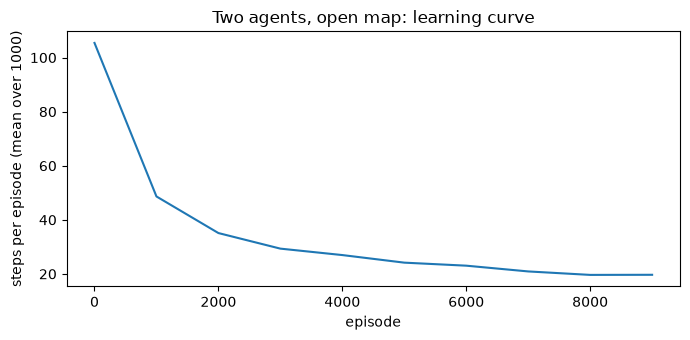

In [38]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)


# mean steps per block of episodes, as a line, saved to figures/
def plot_learning_curve(steps_per_episode, title, filename, block=1000):
    means = [np.mean(steps_per_episode[i:i + block]) for i in range(0, len(steps_per_episode), block)]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(range(0, len(steps_per_episode), block), means)
    ax.set_xlabel("episode")
    ax.set_ylabel(f"steps per episode (mean over {block})")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()


plot_learning_curve(steps, "Two agents, open map: learning curve",
                    "figures/two_agent_navigation_learning_curve.png")


## Step 4: narrow map

A corridor with a single pocket in the middle. The agents have to pass each other, so one of them must step into the pocket and wait.

Best possible: one agent goes straight in 8 steps plus some waiting, the other one takes the detour. In total 10 + 9 steps.

In [39]:
# a corridor with a single pocket in the middle where one agent can step aside
narrow = TwoAgentWarehouse(
    WarehouseGrid("""
####.####
.........
"""),
    starts=[(1, 0), (1, 8)],
    goals=[(1, 8), (1, 0)],
)
narrow_Qs, narrow_steps = train(narrow)
run_greedy(narrow, narrow_Qs)


# # # # . # # # #
A . . . . . . . B

step 1: A RIGHT, B UP
# # # # . # # # #
b A . . . . . . B

step 2: A RIGHT, B UP
# # # # . # # # #
b . A . . . . . B

step 3: A RIGHT, B LEFT
# # # # . # # # #
b . . A . . . B a

step 4: A RIGHT, B WAIT
# # # # . # # # #
b . . . A . . B a

step 5: A DOWN, B LEFT
# # # # . # # # #
b . . . A . B . a

step 6: A UP, B WAIT
# # # # A # # # #
b . . . . . B . a

step 7: A RIGHT, B LEFT
# # # # A # # # #
b . . . . B . . a

step 8: A WAIT, B LEFT
# # # # A # # # #
b . . . B . . . a

step 9: A WAIT, B LEFT
# # # # A # # # #
b . . B . . . . a

step 10: A WAIT, B LEFT
# # # # A # # # #
b . B . . . . . a

step 11: A DOWN, B LEFT
# # # # . # # # #
b B . . A . . . a

step 12: A RIGHT, B LEFT
# # # # . # # # #
B . . . . A . . a

step 13: A RIGHT, B LEFT
# # # # . # # # #
B . . . . . A . a

step 14: A RIGHT, B WAIT
# # # # . # # # #
B . . . . . . A a

step 15: A RIGHT, B RIGHT
# # # # . # # # #
B . . . . . . . A

A done after 15 steps, B after 12 steps, 0 collisions

The result depends on the seed. Both agents always learn to avoid collisions, but not always the shortest path. This is because each agent learns while the other one is also learning and changing its behaviour, so the world does not look the same from one episode to the next.

In [40]:
# same map with different settings and seeds, best possible is 10 and 9 steps
for settings in [{}, {"seed": 1}, {"seed": 2}, {"episodes": 50000, "alpha": 0.2}]:
    test_Qs, _ = train(narrow, **settings)
    print(f"{str(settings):35}", end="")
    run_greedy(narrow, test_Qs, show=False)


{}                                 A done after 15 steps, B after 12 steps, 0 collisions
{'seed': 1}                        A done after 12 steps, B after 10 steps, 0 collisions
{'seed': 2}                        A done after 13 steps, B after 10 steps, 0 collisions
{'episodes': 50000, 'alpha': 0.2}  A done after 9 steps, B after 10 steps, 0 collisions


## Step 5: n-step Q-learning

Ordinary Q-learning updates after one step and bootstraps the rest from `max Q[s']`. Here we wait `n` steps and sum the `n` real rewards before bootstrapping:

`G = r_0 + gamma * r_1 + ... + gamma^(n-1) * r_(n-1) + gamma^n * max Q[s_n]`

`Q[s_0][a_0] += alpha * (G - Q[s_0][a_0])`

* The reward from a collision (`-5`) then reaches back to the action that caused it, not only to the last one.
* Each agent has its own buffer with its last `n` steps (independent Q-learning, as before).
* When an agent reaches its goal there is no future to bootstrap from, so the remaining steps are updated with the real rewards only.
* If the episode ends at the time limit (`max_steps`) that is not a real end, so we bootstrap from `max Q` in the last state.
* `n = 1` is exactly the same as `train()` above.

Source: Sutton & Barto, *Reinforcement Learning: An Introduction* (2nd ed., 2018), chapter 7 (n-step Sarsa, section 7.2). We replace the Sarsa bootstrap `Q[s_n][a_n]` with `max Q[s_n]`, as in n-step Q-learning in Mnih et al. (2016), *Asynchronous Methods for Deep Reinforcement Learning*, ICML.

Note: with epsilon-greedy the `n` rewards follow the behaviour policy, not the greedy policy, so strictly speaking this is not off-policy correct. It usually works fine in small worlds, but keep it in mind if the results look strange.

In [41]:
# update the oldest entry in the buffer with an n-step return
# buffer = [(state, action, reward), ...] with the oldest first
# bootstrap_state = the state to bootstrap from, or None if the agent is done
def nstep_update(Q, buffer, bootstrap_state, alpha, gamma):
    G = 0.0
    if bootstrap_state is not None:
        G = Q[bootstrap_state].max()
    # count backwards: G = r + gamma * G, so gamma^len ends up on the bootstrap
    for _, _, r in reversed(buffer):
        G = r + gamma * G
    s, a, _ = buffer[0]
    Q[s][a] += alpha * (G - Q[s][a])


# same as train(), but with an n-step return. n=1 gives the same result as train()
def train_nstep(env, n=5, episodes=10000, alpha=0.5, gamma=0.99, epsilon=0.1, max_steps=200, seed=0):
    rng = np.random.default_rng(seed)
    Qs = [defaultdict(lambda: np.zeros(len(ACTION_NAMES))) for _ in range(2)]
    steps_per_episode = []

    for episode in range(episodes):
        state = env.reset()
        buffers = [[], []]  # each agent's latest (state, action, reward)

        for t in range(max_steps):
            a = [choose_action(Qs[i], state, epsilon, rng) for i in range(2)]
            next_state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))

            for i in range(2):
                buffers[i].append((state, a[i], rewards[i]))

                if done:
                    # episode over: update all remaining steps without bootstrapping
                    while buffers[i]:
                        nstep_update(Qs[i], buffers[i], None, alpha, gamma)
                        buffers[i].pop(0)
                elif len(buffers[i]) == n:
                    # buffer full: update the oldest step and drop it
                    nstep_update(Qs[i], buffers[i], next_state, alpha, gamma)
                    buffers[i].pop(0)

            state = next_state
            if done:
                break

        # time limit reached: bootstrap from the last state for what is left
        for i in range(2):
            while buffers[i]:
                nstep_update(Qs[i], buffers[i], state, alpha, gamma)
                buffers[i].pop(0)

        steps_per_episode.append(t + 1)

    return Qs, steps_per_episode

### Test: n=1 must give exactly the same as `train()`

In [42]:
env = TwoAgentWarehouse(
    WarehouseGrid(),
    starts=[(0, 0), (0, 9)],
    goals=[(6, 9), (6, 0)],
)
_, steps_1step = train(env, episodes=2000, seed=0)
_, steps_n1 = train_nstep(env, n=1, episodes=2000, seed=0)
print("same learning curve:", steps_1step == steps_n1)

same learning curve: True


### Comparison: different n on the narrow map

Best possible is 10 steps until both are at their goals (checked with breadth-first search over all joint states). We train several seeds per `n` and look at the greedy policy afterwards: how many seeds find the optimum, and how many collisions there are.

In [43]:
# run one greedy episode silently and return (steps until both are done, number of collisions)
def greedy_result(env, Qs, max_steps=50):
    rng = np.random.default_rng(0)
    state = env.reset()
    crashes = 0
    for t in range(1, max_steps + 1):
        a = [choose_action(Qs[i], state, 0.0, rng) for i in range(2)]
        state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))
        crashes += sum(r < STEP_REWARD for r in rewards)
        if done:
            return t, crashes
    return None, crashes  # did not finish


seeds = range(5)  # takes a few minutes, increase for more stable numbers
for n in [1, 3, 5, 10]:
    results = []
    for seed in seeds:
        Qs_n, _ = train_nstep(narrow, n=n, episodes=10000, seed=seed)
        results.append(greedy_result(narrow, Qs_n))
    finished = [t for t, _ in results if t is not None]
    # optimum: the agent that steps aside is done after 10 steps, the other after 9 -> both done after 10
    optimal = sum(t == 10 for t in finished)
    print(f"n={n:2d}: {len(finished)}/{len(seeds)} finished, {optimal}/{len(seeds)} optimal, "
          f"mean {np.mean(finished) if finished else float('nan'):.1f} steps, "
          f"{sum(c for _, c in results)} collisions in total")

n= 1: 5/5 finished, 0/5 optimal, mean 13.4 steps, 0 collisions in total
n= 3: 2/5 finished, 0/5 optimal, mean 14.5 steps, 0 collisions in total
n= 5: 4/5 finished, 0/5 optimal, mean 14.5 steps, 0 collisions in total
n=10: 2/5 finished, 0/5 optimal, mean 16.5 steps, 0 collisions in total


## Step 5b: selfish or cooperative reward

Same narrow map, but we compare the two ways of giving the step reward:

* `selfish`: each agent gets a penalty until it is at its own goal.
* `cooperative`: both get a penalty until the last one is at its goal.

What we want to see: in `cooperative` the fast agent should gain nothing by pushing through, since it waits for the other one anyway. Are there fewer collisions and a shorter time until both are done?

We train several seeds per mode with ordinary Q-learning (`n=1`, which did best above) and measure on the greedy policy: when each agent reached its goal, time until both were done, and the number of collisions.

In [44]:
# run one greedy episode silently: (step when A reached its goal, step when B did, collisions)
def greedy_finish_times(env, Qs, max_steps=50):
    rng = np.random.default_rng(0)
    state = env.reset()
    finished = [None, None]
    crashes = 0
    for t in range(1, max_steps + 1):
        a = [choose_action(Qs[i], state, 0.0, rng) for i in range(2)]
        state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))
        crashes += sum(r < STEP_REWARD for r in rewards)
        for i in range(2):
            if finished[i] is None and state[i] == env.goals[i]:
                finished[i] = t
        if done:
            break
    return finished[0], finished[1], crashes


narrow_layout = """
####.####
.........
"""
seeds = range(10)
for mode in ["selfish", "cooperative"]:
    env_mode = TwoAgentWarehouse(
        WarehouseGrid(narrow_layout),
        starts=[(1, 0), (1, 8)],
        goals=[(1, 8), (1, 0)],
        reward_mode=mode,
    )
    results = [greedy_finish_times(env_mode, train(env_mode, seed=seed)[0]) for seed in seeds]
    both_done = [max(a, b) for a, b, _ in results if a is not None and b is not None]
    print(f"{mode:12s}: {len(both_done)}/{len(seeds)} finished, "
          f"{sum(t == 10 for t in both_done)}/{len(seeds)} optimal (10 steps), "
          f"mean {np.mean(both_done) if both_done else float('nan'):.1f} steps until both done, "
          f"{sum(c for _, _, c in results)} collisions in total")
    for seed, (a, b, c) in zip(seeds, results):
        print(f"    seed {seed}: A {a}, B {b}, collisions {c}")


selfish     : 9/10 finished, 0/10 optimal (10 steps), mean 12.9 steps until both done, 0 collisions in total
    seed 0: A 15, B 12, collisions 0
    seed 1: A 12, B 10, collisions 0
    seed 2: A 13, B 10, collisions 0
    seed 3: A 13, B 11, collisions 0
    seed 4: A 11, B 14, collisions 0
    seed 5: A 11, B 14, collisions 0
    seed 6: A 11, B 10, collisions 0
    seed 7: A 11, B 13, collisions 0
    seed 8: A 11, B 10, collisions 0
    seed 9: A None, B None, collisions 0
cooperative : 9/10 finished, 1/10 optimal (10 steps), mean 12.2 steps until both done, 0 collisions in total
    seed 0: A 11, B 11, collisions 0
    seed 1: A 12, B 13, collisions 0
    seed 2: A None, B None, collisions 0
    seed 3: A 10, B 10, collisions 0
    seed 4: A 13, B 13, collisions 0
    seed 5: A 10, B 12, collisions 0
    seed 6: A 14, B 13, collisions 0
    seed 7: A 12, B 13, collisions 0
    seed 8: A 11, B 11, collisions 0
    seed 9: A 13, B 13, collisions 0


## Step 6: pick one item at a time and deliver it

The agent picks an item, carries it to the drop-off cell `D` (bottom middle) and then fetches the next one.

* The state is `(position, mask, carrying)`. `mask` has bit `i` set when item `i` has left its shelf (picked or delivered). `carrying` is `True` when the agent holds an item. Delivered items are the ones in `mask` that are not being carried right now.
* `PICK` picks the item if the agent stands on a pick spot (the floor cell next to the shelf) and is not already carrying something.
* Delivery happens automatically when a carrying agent steps on `D`. A separate `DROP` action could be added if wanted.
* Reward: `-1` per step, `+5` for picking an item, `+10` for delivering one.
* Penalty: `-2` extra for a `PICK` where there is no item, or while already carrying one.
* The episode ends when the last item is delivered. With `finish=(row, col)` the agent also has to stand there (e.g. the charging station).

`transition()` changes nothing, it only computes what would happen, so the same rules are used by `step()` and by the search that computes the best possible solution.

In [45]:
PICK_REWARD = 5          # picking an item
DELIVER_REWARD = 10      # delivering an item at D
BAD_PICK_PENALTY = -2    # extra penalty: PICK with no item nearby, or while already carrying one

# the old actions plus PICK
ACTIONS_PICK = list(ACTIONS) + ["PICK"]   # UP, DOWN, LEFT, RIGHT, WAIT, PICK


class PickupWarehouse:
    def __init__(self, grid, items, start=None, dropoff=None, finish=None):
        self.grid = grid                # WarehouseGrid with the items placed
        self.items = list(items)        # e.g. [0, 1, 2], index in the list = bit in the mask
        self.start = grid.start if start is None else start
        # drop-off: bottom middle unless given
        self.dropoff = (grid.n_rows - 1, grid.n_cols // 2) if dropoff is None else dropoff
        self.finish = finish            # None = done as soon as the last item is delivered
        self.full_mask = (1 << len(self.items)) - 1

        for item in self.items:
            if item not in grid.item_to_shelf:
                raise ValueError(f"Item {item} is not on any shelf.")
        if self.dropoff not in grid.walkable_cells:
            raise ValueError(f"Drop-off {self.dropoff} is not a floor cell.")
        self.reset()

    def reset(self):
        self.pos = self.start
        self.mask = 0              # items that have left their shelf
        self.carrying = False      # is the agent holding an item?
        return (self.pos, self.mask, self.carrying)

    # compute what an action does, without changing anything
    def transition(self, pos, mask, carrying, action):
        reward = STEP_REWARD
        if action == "PICK":
            picked = False
            if not carrying:
                for i, item in enumerate(self.items):
                    already_gone = mask & (1 << i)
                    if not already_gone and pos in self.grid.pick_spots_for_item(item):
                        mask |= 1 << i
                        carrying = True
                        picked = True
                        reward += PICK_REWARD
                        break      # one item per PICK
            if not picked:
                reward += BAD_PICK_PENALTY   # no item here, or hands already full
        else:
            dr, dc = ACTIONS[action]
            new = (pos[0] + dr, pos[1] + dc)
            if new in self.grid.walkable_cells:   # shelf or outside -> stay
                pos = new
            if carrying and pos == self.dropoff:  # deliver automatically
                carrying = False
                reward += DELIVER_REWARD

        all_delivered = mask == self.full_mask and not carrying
        done = all_delivered and (self.finish is None or pos == self.finish)
        return pos, mask, carrying, reward, done

    def step(self, action):
        self.pos, self.mask, self.carrying, reward, done = self.transition(
            self.pos, self.mask, self.carrying, action)
        return (self.pos, self.mask, self.carrying), reward, done

    def n_delivered(self):
        return bin(self.mask).count("1") - int(self.carrying)

    # draw the map: S = start, D = drop-off, A = the agent (C when carrying an item),
    # digit = item still on its shelf, x = item that has left its shelf
    def render(self):
        grid = np.full((self.grid.n_rows, self.grid.n_cols), ".")
        for cell in self.grid.shelf_cells:
            grid[cell] = "#"
        for i, item in enumerate(self.items):
            shelf = self.grid.item_to_shelf[item]
            grid[shelf] = "x" if self.mask & (1 << i) else str(item)
        grid[self.start] = "S"
        grid[self.dropoff] = "D"
        grid[self.pos] = "C" if self.carrying else "A"
        for row in grid:
            print(" ".join(row))
        print()


# minimum number of steps to deliver everything (breadth-first over all (position, mask, carrying),
# same rules as step)
def optimal_steps(env):
    first = (env.start, 0, False)
    seen = {first}
    queue = deque([(first, 0)])
    while queue:
        (pos, mask, carrying), d = queue.popleft()
        for action in ACTIONS_PICK:
            new_pos, new_mask, new_carrying, _, done = env.transition(pos, mask, carrying, action)
            if done:
                return d + 1
            nxt = (new_pos, new_mask, new_carrying)
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, d + 1))
    return None

### Training

Same n-step Q-learning as in step 5 (`nstep_update` is reused), but for one agent. `n=1` is ordinary Q-learning.

With `n=5` a low `alpha` (0.1) is needed. The five rewards contain random epsilon steps, and with `alpha=0.5` the updates are so noisy that the agent often gets stuck.

In [46]:
# like choose_action, but picks among all actions including PICK
def choose_action_pick(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return rng.integers(len(ACTIONS_PICK))
    q = Q[state]
    best = np.flatnonzero(q == q.max())
    return rng.choice(best)


def train_pickup(env, n=1, episodes=3000, alpha=0.5, gamma=0.99, epsilon=0.1, max_steps=300, seed=0):
    rng = np.random.default_rng(seed)
    Q = defaultdict(lambda: np.zeros(len(ACTIONS_PICK)))
    steps_per_episode = []

    for episode in range(episodes):
        state = env.reset()
        buffer = []

        for t in range(max_steps):
            a = choose_action_pick(Q, state, epsilon, rng)
            next_state, reward, done = env.step(ACTIONS_PICK[a])
            buffer.append((state, a, reward))

            if done:
                # done: update everything left without bootstrapping
                while buffer:
                    nstep_update(Q, buffer, None, alpha, gamma)
                    buffer.pop(0)
                break
            if len(buffer) == n:
                nstep_update(Q, buffer, next_state, alpha, gamma)
                buffer.pop(0)
            state = next_state

        # time limit reached: bootstrap from the last state
        while buffer:
            nstep_update(Q, buffer, state, alpha, gamma)
            buffer.pop(0)

        steps_per_episode.append(t + 1)

    return Q, steps_per_episode


# run one greedy episode and print what the agent does
def run_greedy_pickup(env, Q, max_steps=150, show=True):
    rng = np.random.default_rng(0)
    state = env.reset()
    if show:
        env.render()
    bad_picks = 0
    for t in range(1, max_steps + 1):
        a = choose_action_pick(Q, state, 0.0, rng)
        picked_before, delivered_before = bin(env.mask).count("1"), env.n_delivered()
        state, reward, done = env.step(ACTIONS_PICK[a])
        note = ""
        if bin(env.mask).count("1") > picked_before:
            note = "  <- picked an item"
        elif env.n_delivered() > delivered_before:
            note = "  <- delivered"
        elif ACTIONS_PICK[a] == "PICK":
            note = "  <- useless PICK (penalty)"
            bad_picks += 1
        if show:
            print(f"step {t:2d}: {ACTIONS_PICK[a]:5s} -> {state[0]}{note}")
        if done:
            break
    if show:
        print()
        env.render()
    return (t if done else None), env.n_delivered(), bad_picks

### Test: one agent, 9x9, three items

The map is 9x9 with four rows of single-depth shelves. Three items are placed on random shelves (`seed=1`). The agent starts top left, picks one item at a time and drops it at `D` (bottom middle). The best possible solution is computed exactly for comparison.

In [47]:
# 9x9: 4 shelf rows with depth 1, 2 shelves per row with width 3
layout = make_layout(n_shelf_rows=4, shelves_per_row=2, shelf_width=3, shelf_depth=1)
grid = WarehouseGrid(layout)
grid.place_items_randomly([0, 1, 2], seed=1)
env = PickupWarehouse(grid, items=[0, 1, 2], finish=(0,0))   # drop-off: bottom middle
print(f"size {grid.n_rows}x{grid.n_cols}, items on shelves: {grid.item_to_shelf}, drop-off: {env.dropoff}")
env.render()

best = optimal_steps(env)
print(f"best possible: {best} steps\n")

Q, steps = train_pickup(env, n=5, alpha=0.1, episodes=5000, seed=0)
for i in range(0, len(steps), 1000):
    print(f"episodes {i:4d}-{i + 999}: {np.mean(steps[i:i + 1000]):6.1f} steps")
print()

finished, delivered, bad_picks = run_greedy_pickup(env, Q)
print(f"greedy policy: {finished} steps (best {best}), {delivered} items delivered, {bad_picks} useless PICKs")

size 9x9, items on shelves: {0: (3, 7), 1: (3, 6), 2: (7, 1)}, drop-off: (8, 4)
A . . . . . . . .
. # # # . # # # .
. . . . . . . . .
. # # # . # 1 0 .
. . . . . . . . .
. # # # . # # # .
. . . . . . . . .
. 2 # # . # # # .
. . . . D . . . .

best possible: 51 steps

episodes    0-999:  155.6 steps
episodes 1000-1999:   58.4 steps
episodes 2000-2999:   58.6 steps
episodes 3000-3999:   57.6 steps
episodes 4000-4999:   59.3 steps

A . . . . . . . .
. # # # . # # # .
. . . . . . . . .
. # # # . # 1 0 .
. . . . . . . . .
. # # # . # # # .
. . . . . . . . .
. 2 # # . # # # .
. . . . D . . . .

step  1: RIGHT -> (0, 1)
step  2: RIGHT -> (0, 2)
step  3: RIGHT -> (0, 3)
step  4: RIGHT -> (0, 4)
step  5: DOWN  -> (1, 4)
step  6: DOWN  -> (2, 4)
step  7: DOWN  -> (3, 4)
step  8: DOWN  -> (4, 4)
step  9: RIGHT -> (4, 5)
step 10: RIGHT -> (4, 6)
step 11: RIGHT -> (4, 7)
step 12: PICK  -> (4, 7)  <- picked an item
step 13: LEFT  -> (4, 6)
step 14: LEFT  -> (4, 5)
step 15: LEFT  -> (4, 4)
step 16: D

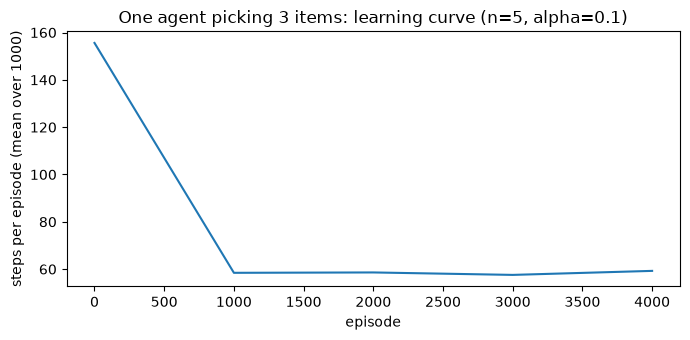

In [48]:
plot_learning_curve(steps, "One agent picking 3 items: learning curve (n=5, alpha=0.1)",
                    "figures/pickup_learning_curve.png")


## Step 7: two agents picking in the same warehouse

Now we combine step 2 (collision rules) and step 6 (picking). Like real picking robots, each agent has its own items, but they share the warehouse and the drop-off cell `D`, so they can get in each other's way.

* Each agent has its own list of items, its own start which is also its goal, and they share `D`.
* What agent `i` observes (`obs(i)`): its own position, its mask, whether it is carrying something, and where the other agent is. Not the other agent's items, otherwise the Q-table gets too big.
* The collision rules are the same as in step 2, also at `D`. `PICK` does not move the agent, so it cannot collide.
* Rewards: same as in step 6 (`-1` per step, `+5` pick, `+10` delivery, `-2` useless `PICK`) plus `-5` for a collision. An agent is done when everything is delivered and it is back on its start. `reward_mode` as in step 5b: `selfish` gives `0` once done, `cooperative` gives `-1` until both are done.

The best possible solution for two agents is expensive to compute exactly (all combinations of both states), so we use a lower bound: each agent alone in the warehouse with its items, computed with `optimal_steps` from step 6. Nobody can be faster than that, and the gap to that bound is the price of sharing the warehouse.

In [49]:
class TwoAgentPickupWarehouse:
    """Two agents with the PickupWarehouse rules. Each agent has its own items, its own start (= goal)
    and they share the drop-off cell D. Collision rules as in TwoAgentWarehouse."""

    def __init__(self, grid, items_per_agent, starts, dropoff=None, reward_mode="selfish"):
        self.grid = grid
        self.items = [list(items) for items in items_per_agent]   # e.g. [[0, 1], [2, 3]]
        self.starts = list(starts)                                 # one start per agent, also its goal
        self.dropoff = (grid.n_rows - 1, grid.n_cols // 2) if dropoff is None else dropoff
        self.full_masks = [(1 << len(items)) - 1 for items in self.items]
        if reward_mode not in ("selfish", "cooperative"):
            raise ValueError(f"Unknown reward_mode: {reward_mode}")
        self.reward_mode = reward_mode

        for items in self.items:
            for item in items:
                if item not in grid.item_to_shelf:
                    raise ValueError(f"Item {item} is not on any shelf.")
        if self.dropoff not in grid.walkable_cells:
            raise ValueError(f"Drop-off {self.dropoff} is not a floor cell.")
        self.reset()

    def reset(self):
        self.pos = list(self.starts)
        self.mask = [0, 0]
        self.carrying = [False, False]
        return self.state()

    # the full state, used by render and done
    def state(self):
        return tuple((self.pos[i], self.mask[i], self.carrying[i]) for i in range(2))

    # what agent i observes: its own state plus where the other one is
    def obs(self, i):
        return (self.pos[i], self.mask[i], self.carrying[i], self.pos[1 - i])

    # is agent i completely done? everything delivered and back on its start
    def finished(self, i):
        return (self.mask[i] == self.full_masks[i]
                and not self.carrying[i]
                and self.pos[i] == self.starts[i])

    def step(self, actions):
        old = list(self.pos)

        # 1. where do the agents want to go? PICK and WAIT = stay, a finished agent stays
        wanted = []
        for i in range(2):
            if self.finished(i) or actions[i] == "PICK":
                wanted.append(old[i])
            else:
                dr, dc = ACTIONS[actions[i]]
                new = (old[i][0] + dr, old[i][1] + dc)
                wanted.append(new if new in self.grid.walkable_cells else old[i])

        # 2. same cell or swapping places -> both stay
        same_cell = wanted[0] == wanted[1]
        swap = wanted[0] == old[1] and wanted[1] == old[0]
        new = old if (same_cell or swap) else wanted

        # 3. reward per agent: step, collision, pick, delivery
        rewards = []
        for i in range(2):
            if self.finished(i):
                rewards.append(0)
                continue
            reward = STEP_REWARD
            if wanted[i] != old[i] and new[i] == old[i]:
                reward += CRASH_REWARD           # blocked by the other agent

            if actions[i] == "PICK":
                picked = False
                if not self.carrying[i]:
                    for b, item in enumerate(self.items[i]):
                        already_gone = self.mask[i] & (1 << b)
                        if not already_gone and old[i] in self.grid.pick_spots_for_item(item):
                            self.mask[i] |= 1 << b
                            self.carrying[i] = True
                            picked = True
                            reward += PICK_REWARD
                            break
                if not picked:
                    reward += BAD_PICK_PENALTY
            elif self.carrying[i] and new[i] == self.dropoff:
                self.carrying[i] = False
                reward += DELIVER_REWARD
            rewards.append(reward)

        self.pos = list(new)
        done = self.finished(0) and self.finished(1)

        # cooperative: a finished agent still gets -1 until both are done
        if self.reward_mode == "cooperative" and not done:
            for i in range(2):
                if self.finished(i) and rewards[i] == 0:
                    rewards[i] = STEP_REWARD
        return self.state(), rewards, done

    def n_delivered(self, i):
        return bin(self.mask[i]).count("1") - int(self.carrying[i])

    # S/T = starts, D = drop-off, A/B = the agents (a/b when carrying), digit = item on shelf, x = picked
    def render(self):
        grid = np.full((self.grid.n_rows, self.grid.n_cols), ".")
        for cell in self.grid.shelf_cells:
            grid[cell] = "#"
        for i in range(2):
            for b, item in enumerate(self.items[i]):
                grid[self.grid.item_to_shelf[item]] = "x" if self.mask[i] & (1 << b) else str(item)
        for start, name in zip(self.starts, "ST"):
            grid[start] = name
        grid[self.dropoff] = "D"
        for i, name in enumerate("AB"):
            grid[self.pos[i]] = name.lower() if self.carrying[i] else name
        for row in grid:
            print(" ".join(row))
        print()


# lower bound: each agent alone in the warehouse with its items (ignoring the other one)
def lower_bound_steps(env):
    bounds = []
    for i in range(2):
        solo = PickupWarehouse(env.grid, items=env.items[i], start=env.starts[i],
                               dropoff=env.dropoff, finish=env.starts[i])
        bounds.append(optimal_steps(solo))
    return bounds


### Training

Same n-step Q-learning as before, one Q-table per agent on `obs(i)`. One new parameter: `q_init`, the initial value of all Q-values.

So far all Q-values started at `0`. That is "optimistic" when the real values are negative: a state the agent has never visited looks better than every state it has visited, so the greedy policy is drawn towards new states. In selfish mode there are real zeros (done = `0` per step), so it still works. In cooperative mode everything is negative until both are done, and then it becomes a problem, see the test below.

In [50]:
# n-step Q-learning for two picking agents, one Q-table per agent on obs(i)
def train_two_pickup(env, n=1, episodes=30000, alpha=0.5, gamma=0.99, epsilon=0.1,
                     max_steps=300, seed=0, q_init=0.0):
    rng = np.random.default_rng(seed)
    # float(q_init): otherwise Q becomes an integer array and every update is truncated
    Qs = [defaultdict(lambda: np.full(len(ACTIONS_PICK), float(q_init))) for _ in range(2)]
    steps_per_episode = []

    for episode in range(episodes):
        env.reset()
        obs = [env.obs(0), env.obs(1)]
        buffers = [[], []]

        for t in range(max_steps):
            a = [choose_action_pick(Qs[i], obs[i], epsilon, rng) for i in range(2)]
            _, rewards, done = env.step((ACTIONS_PICK[a[0]], ACTIONS_PICK[a[1]]))
            next_obs = [env.obs(0), env.obs(1)]

            for i in range(2):
                buffers[i].append((obs[i], a[i], rewards[i]))
                if done:
                    while buffers[i]:
                        nstep_update(Qs[i], buffers[i], None, alpha, gamma)
                        buffers[i].pop(0)
                elif len(buffers[i]) == n:
                    nstep_update(Qs[i], buffers[i], next_obs[i], alpha, gamma)
                    buffers[i].pop(0)

            obs = next_obs
            if done:
                break

        for i in range(2):
            while buffers[i]:
                nstep_update(Qs[i], buffers[i], obs[i], alpha, gamma)
                buffers[i].pop(0)
        steps_per_episode.append(t + 1)

    return Qs, steps_per_episode


# greedy run: (step when A is done, step when B is done, collisions, items delivered per agent)
def run_greedy_two_pickup(env, Qs, max_steps=200, show=False):
    rng = np.random.default_rng(0)
    env.reset()
    finished = [None, None]
    crashes = 0
    if show:
        env.render()
    for t in range(1, max_steps + 1):
        a = [choose_action_pick(Qs[i], env.obs(i), 0.0, rng) for i in range(2)]
        _, rewards, done = env.step((ACTIONS_PICK[a[0]], ACTIONS_PICK[a[1]]))
        crashes += sum(r <= STEP_REWARD + CRASH_REWARD for r in rewards)
        for i in range(2):
            if finished[i] is None and env.finished(i):
                finished[i] = t
        if show:
            print(f"step {t}: A {ACTIONS_PICK[a[0]]}, B {ACTIONS_PICK[a[1]]}  rewards {rewards}")
            env.render()
        if done:
            break
    return finished[0], finished[1], crashes, [env.n_delivered(0), env.n_delivered(1)]


### Test: 9x9, two items per agent

Same map as in step 6. Four items on random shelves (`seed=1`), agent A gets items 0 and 1, agent B items 2 and 3. A starts top left, B top right, both deliver at `D` (bottom middle) and must return to their own start.

In [51]:
layout = make_layout(n_shelf_rows=4, shelves_per_row=2, shelf_width=3, shelf_depth=1)
grid2 = WarehouseGrid(layout)
grid2.place_items_randomly([0, 1, 2, 3], seed=1)
env2 = TwoAgentPickupWarehouse(grid2, items_per_agent=[[0, 1], [2, 3]], starts=[(0, 0), (0, 8)])
print(f"items on shelves: {grid2.item_to_shelf}, drop-off: {env2.dropoff}")
env2.render()

bounds = lower_bound_steps(env2)
print(f"lower bound, alone in the warehouse: A {bounds[0]} steps, B {bounds[1]} steps")


items on shelves: {0: (5, 7), 1: (3, 7), 2: (7, 6), 3: (3, 5)}, drop-off: (8, 4)
A . . . . . . . B
. # # # . # # # .
. . . . . . . . .
. # # # . 3 # 1 .
. . . . . . . . .
. # # # . # # 0 .
. . . . . . . . .
. # # # . # 2 # .
. . . . D . . . .

lower bound, alone in the warehouse: A 42 steps, B 30 steps


In [52]:
Qs2, steps2 = train_two_pickup(env2, q_init=-30)
for i in range(0, len(steps2), 3000):
    print(f"episodes {i:5d}-{i + 2999}: {np.mean(steps2[i:i + 3000]):6.1f} steps")
print()

a_done, b_done, crashes, delivered = run_greedy_two_pickup(env2, Qs2)
print(f"greedy policy: A done after {a_done} steps (bound {bounds[0]}), B after {b_done} (bound {bounds[1]}), "
      f"{crashes} collisions, delivered {delivered}")


episodes     0-2999:  138.6 steps
episodes  3000-5999:   75.4 steps
episodes  6000-8999:   72.1 steps
episodes  9000-11999:   70.2 steps
episodes 12000-14999:   71.2 steps
episodes 15000-17999:   69.2 steps
episodes 18000-20999:   71.2 steps
episodes 21000-23999:   72.6 steps
episodes 24000-26999:   70.2 steps
episodes 27000-29999:   67.9 steps

greedy policy: A done after 56 steps (bound 42), B after 33 (bound 30), 0 collisions, delivered [2, 2]


### The learned behaviour, frame by frame

The learning curve shows *that* the agents learn. These frames show *what* they learned. A frame is drawn at every pick, every delivery, every `WAIT` and every collision, with the actions in the title and the path since the previous frame as a line. The `WAIT` frames are the interesting ones: that is where an agent gives way to the other one.

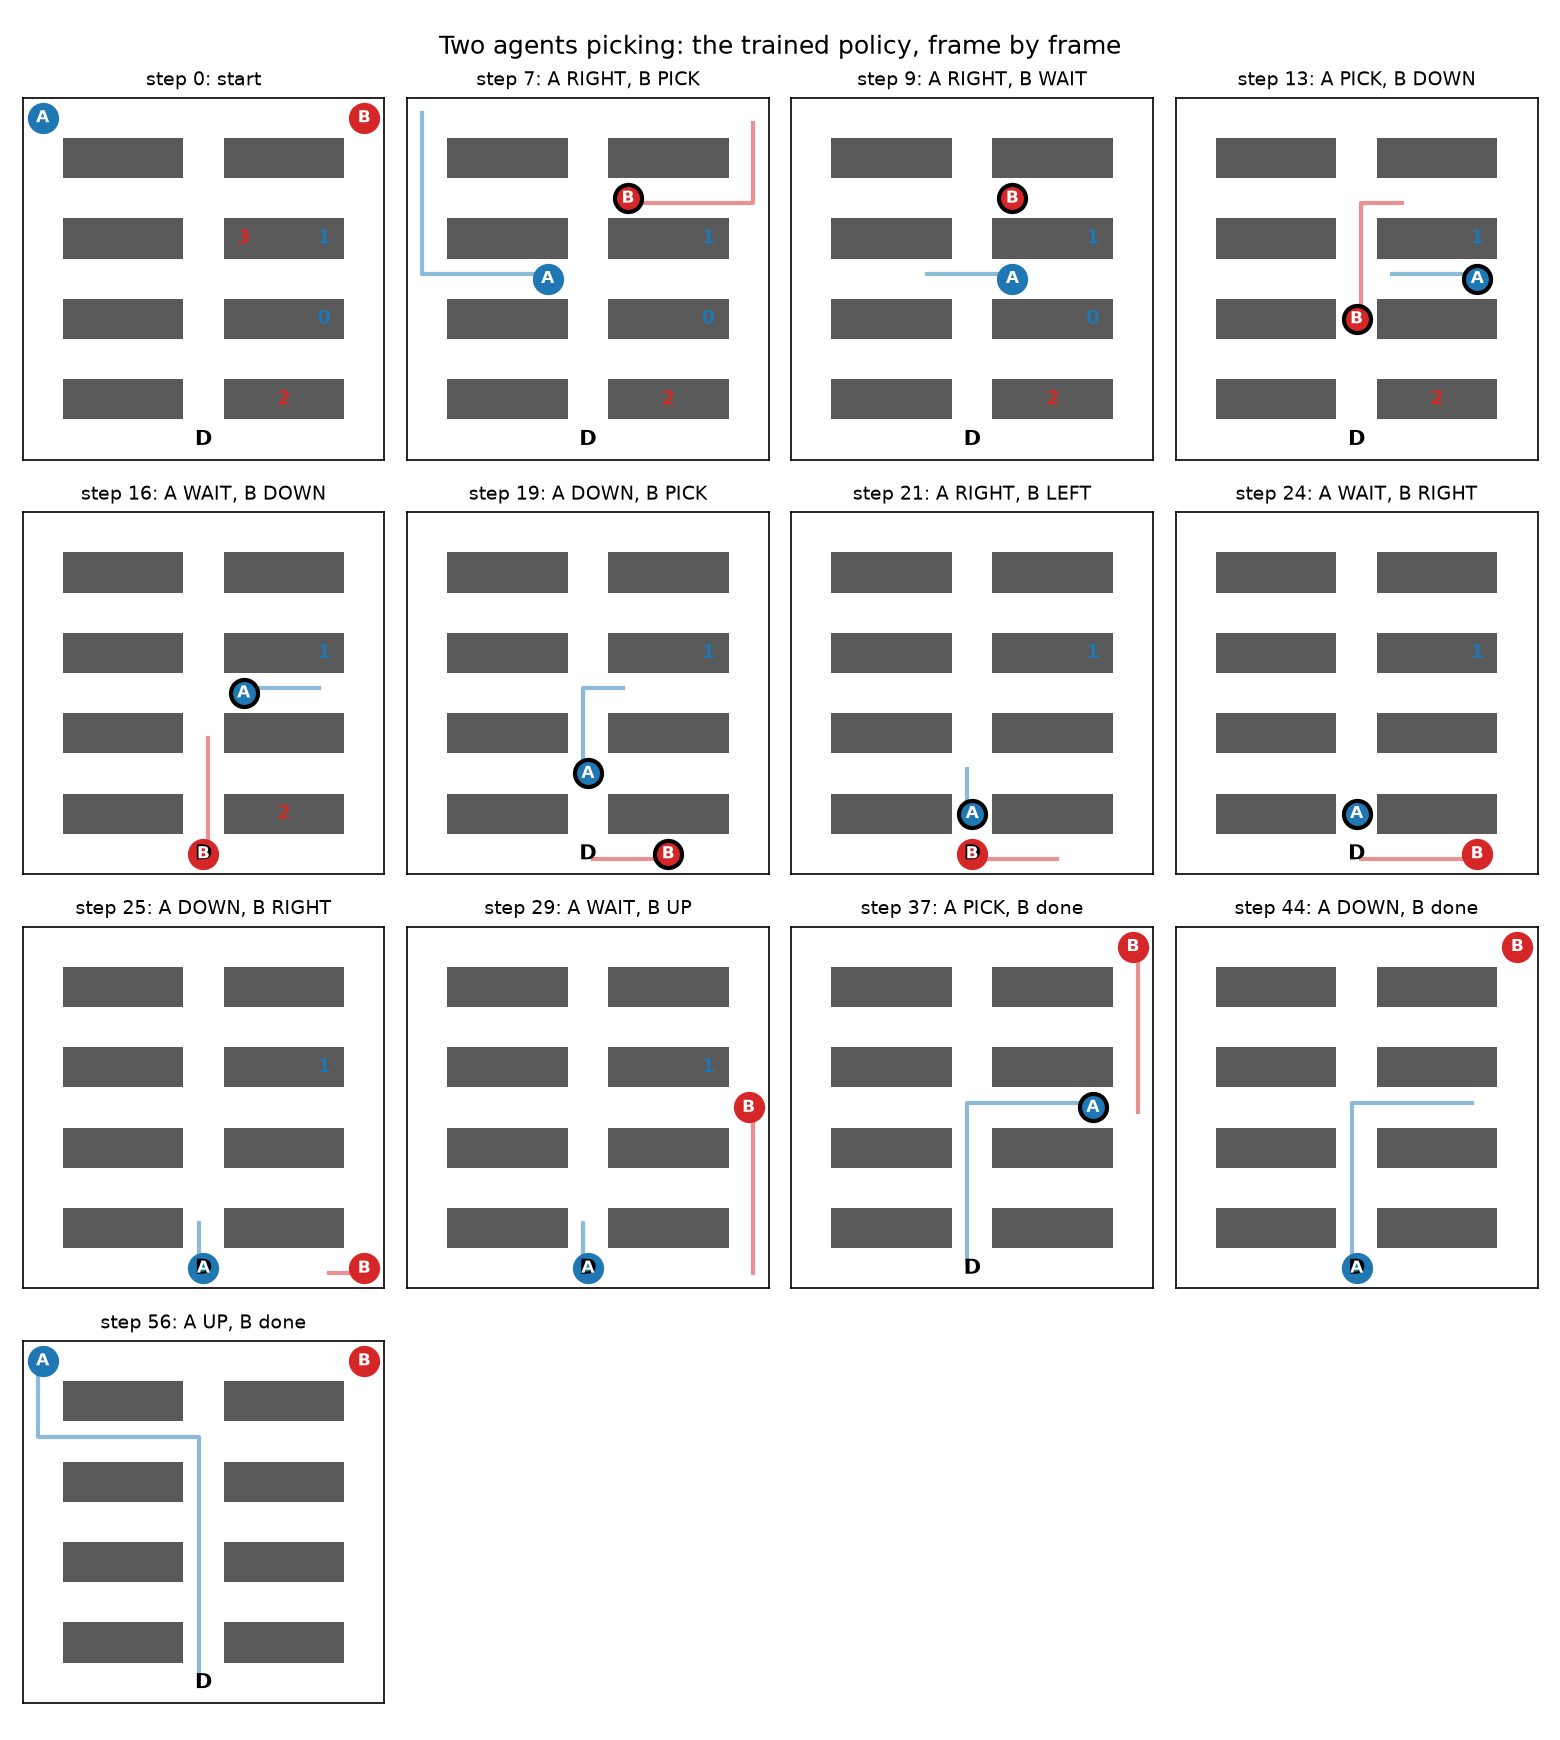

[0, 7, 9, 13, 16, 19, 21, 24, 25, 29, 37, 44, 56]

In [53]:
# replay the greedy policy: state after every step, plus the actions and rewards that led there
def greedy_trace(env, Qs, max_steps=200):
    rng = np.random.default_rng(0)
    env.reset()
    states, actions, rewards = [env.state()], [None], [None]
    for t in range(max_steps):
        a = [ACTIONS_PICK[choose_action_pick(Qs[i], env.obs(i), 0.0, rng)] for i in range(2)]
        _, r, done = env.step(tuple(a))
        states.append(env.state())
        actions.append(a)
        rewards.append(r)
        if done:
            break
    return states, actions, rewards


def is_finished(env, state, i):
    pos, mask, carrying = state[i]
    return mask == env.full_masks[i] and not carrying and pos == env.starts[i]


# the steps worth a frame: start, every pick, every delivery, every WAIT, every collision, and the end
def key_steps(env, states, actions, rewards):
    keys = {0, len(states) - 1}
    for t in range(1, len(states)):
        for i in range(2):
            picked = states[t][i][1] != states[t - 1][i][1]
            delivered = states[t][i][2] != states[t - 1][i][2] and not picked
            waited = actions[t][i] == "WAIT" and not is_finished(env, states[t - 1], i)
            blocked = rewards[t][i] <= STEP_REWARD + CRASH_REWARD
            if picked or delivered or waited or blocked:
                keys.add(t)
    return sorted(keys)


# one frame: the map at step t, the path since the previous frame, the actions in the title
def draw_frame(ax, env, states, actions, t, prev_t):
    img = np.ones((env.grid.n_rows, env.grid.n_cols))
    for r, c in env.grid.shelf_cells:
        img[r, c] = 0.35
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    colors = ["tab:blue", "tab:red"]
    state = states[t]
    for i in range(2):
        for b, item in enumerate(env.items[i]):
            if not state[i][1] & (1 << b):          # still on its shelf
                r, c = env.grid.item_to_shelf[item]
                ax.text(c, r, str(item), ha="center", va="center", color=colors[i],
                        fontweight="bold", fontsize=9)
    r, c = env.dropoff
    ax.text(c, r, "D", ha="center", va="center", fontweight="bold", fontsize=10)
    for i in range(2):
        offset = -0.12 if i == 0 else 0.12
        trail = [states[s][i][0] for s in range(prev_t, t + 1)]
        ax.plot([c + offset for _, c in trail], [r + offset for r, _ in trail],
                color=colors[i], linewidth=2, alpha=0.5)
    for i, name in enumerate("AB"):
        pos, _, carrying = state[i]
        ax.plot(pos[1], pos[0], "o", color=colors[i], markersize=13,
                markeredgecolor="black" if carrying else colors[i], markeredgewidth=2)
        ax.text(pos[1], pos[0], name, ha="center", va="center", color="white",
                fontsize=8, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])
    if t == 0:
        ax.set_title("step 0: start", fontsize=9)
    else:
        labels = ["done" if is_finished(env, states[t - 1], i) else actions[t][i] for i in range(2)]
        ax.set_title(f"step {t}: A {labels[0]}, B {labels[1]}", fontsize=9)


def plot_snapshots(env, Qs, title, filename, per_row=4):
    states, actions, rewards = greedy_trace(env, Qs)
    keys = key_steps(env, states, actions, rewards)
    n_rows = (len(keys) + per_row - 1) // per_row
    fig, axes = plt.subplots(n_rows, per_row, figsize=(2.6 * per_row, 2.9 * n_rows))
    prev = 0
    for ax, t in zip(axes.flat, keys):
        draw_frame(ax, env, states, actions, t, prev)
        prev = t
    for ax in list(axes.flat)[len(keys):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()
    return keys


# settings (selfish, q_init=-30) and the legend go in the report caption, not in the title
plot_snapshots(env2, Qs2, "Two agents picking: the trained policy, frame by frame",
               "figures/two_agent_pickup_snapshots.png")


### Selfish vs cooperative, and what `q_init` does

We run both reward modes with three different initial Q-values and three seeds each. For every run we record when each agent is done, the collisions, and the gap to the lower bound (steps beyond what the agent would need alone). Collisions are almost always 0 after training, so the gap is the more informative number. 18 training runs, each about a minute.

In [54]:
sweep_seeds = range(3)
results2 = {}   # (q_init, mode) -> list of (greedy result, learning curve), one per seed
for q_init in [0, -30, -100]:
    for mode in ["selfish", "cooperative"]:
        runs = []
        for seed in sweep_seeds:
            env_mode = TwoAgentPickupWarehouse(grid2, items_per_agent=[[0, 1], [2, 3]],
                                               starts=[(0, 0), (0, 8)], reward_mode=mode)
            Qs_mode, steps_mode = train_two_pickup(env_mode, q_init=q_init, seed=seed)
            runs.append((run_greedy_two_pickup(env_mode, Qs_mode), steps_mode))
        results2[(q_init, mode)] = runs

        done = [(a, b) for (a, b, _, _), _ in runs if a is not None and b is not None]
        crashes = sum(c for (_, _, c, _), _ in runs)
        if done:
            gap_a = np.mean([a - bounds[0] for a, _ in done])
            gap_b = np.mean([b - bounds[1] for _, b in done])
            summary = (f"mean A {np.mean([a for a, _ in done]):5.1f} (+{gap_a:.1f}), "
                       f"B {np.mean([b for _, b in done]):5.1f} (+{gap_b:.1f})")
        else:
            summary = "never finished"
        print(f"q_init {q_init:5d}, {mode:12s}: finished {len(done)}/{len(sweep_seeds)}, "
              f"{summary}, collisions {crashes}")


q_init     0, selfish     : finished 3/3, mean A  45.0 (+3.0), B  30.0 (+0.0), collisions 0
q_init     0, cooperative : finished 0/3, never finished, collisions 0
q_init   -30, selfish     : finished 2/3, mean A  55.0 (+13.0), B  34.5 (+4.5), collisions 0
q_init   -30, cooperative : finished 3/3, mean A  52.3 (+10.3), B  34.0 (+4.0), collisions 0
q_init  -100, selfish     : finished 3/3, mean A  58.3 (+16.3), B  40.3 (+10.3), collisions 0
q_init  -100, cooperative : finished 2/3, mean A  63.0 (+21.0), B  32.0 (+2.0), collisions 0


How to read it: `+5.0` after a mean means the agent took 5 steps more than it would need alone in the warehouse. That is the price of sharing it.

With three seeds the picture is:

* `q_init = 0`: selfish is at its best here (A +3, B +0, all seeds finish). Cooperative never finishes: every unvisited state looks better than finishing, so the agents wander instead of picking.
* `q_init = -30`: cooperative finishes every seed, selfish two of three. Both are slower than selfish at 0, so this is not a better setting, it is the only one where both reward modes work.
* `q_init = -100`: both modes get slower (A +16 and +21). The agents settle for the first route they find and stop exploring.

So the initial Q-value is not a detail: with all rewards negative until the episode ends, 0 is an optimistic start that drives exploration, which selfish can use but cooperative cannot. We use `-30` for the comparison between the two reward modes because it is the setting where both learn.

The learning curves below are the mean over the seeds (mean steps per 1000 episodes) and are saved as a figure for the report.

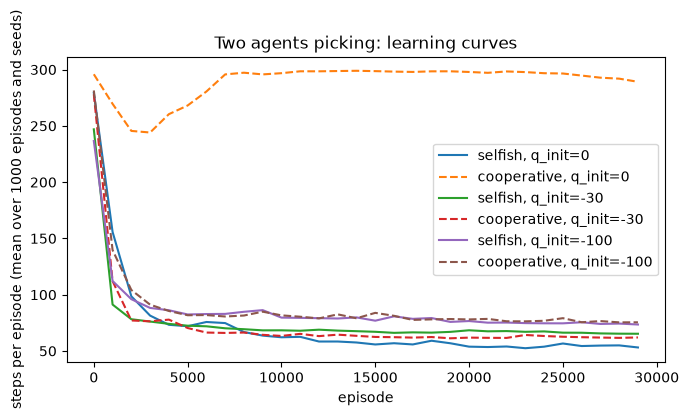

In [55]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 4))
for (q_init, mode), runs in results2.items():
    curves = np.array([[np.mean(steps_mode[i:i + 1000]) for i in range(0, len(steps_mode), 1000)]
                       for _, steps_mode in runs])
    means = curves.mean(axis=0)
    ax.plot(range(0, len(runs[0][1]), 1000), means, label=f"{mode}, q_init={q_init}",
            linestyle="-" if mode == "selfish" else "--")
ax.set_xlabel("episode")
ax.set_ylabel("steps per episode (mean over 1000 episodes and seeds)")
ax.set_title("Two agents picking: learning curves")
ax.legend()
fig.tight_layout()
fig.savefig("figures/two_agent_pickup_learning_curve.png", dpi=150)
plt.show()


### Five seeds on the main comparison: selfish vs cooperative with `q_init = -30`

The sweep above uses three seeds per setting. For the comparison we care most about we train five seeds per reward mode and look at the greedy policy: when each agent is done, the gap to the lower bound, how many seeds finish at all, and the collisions. Takes about ten minutes.

In [56]:
seeds = range(5)
for mode in ["selfish", "cooperative"]:
    rows = []
    for seed in seeds:
        env_mode = TwoAgentPickupWarehouse(grid2, items_per_agent=[[0, 1], [2, 3]],
                                           starts=[(0, 0), (0, 8)], reward_mode=mode)
        Qs_mode, _ = train_two_pickup(env_mode, q_init=-30, seed=seed)
        rows.append(run_greedy_two_pickup(env_mode, Qs_mode))
    print(f"{mode} (q_init=-30, {len(seeds)} seeds)")
    for seed, (a, b, crashes, delivered) in zip(seeds, rows):
        print(f"  seed {seed}: A {a}, B {b}, collisions {crashes}, delivered {delivered}")
    done = [(a, b) for a, b, _, _ in rows if a is not None and b is not None]
    if done:
        print(f"  finished {len(done)}/{len(seeds)}, "
              f"mean A {np.mean([a for a, _ in done]):.1f} (+{np.mean([a - bounds[0] for a, _ in done]):.1f}), "
              f"B {np.mean([b for _, b in done]):.1f} (+{np.mean([b - bounds[1] for _, b in done]):.1f}), "
              f"both done {np.mean([max(a, b) for a, b in done]):.1f}, "
              f"collisions in total {sum(c for _, _, c, _ in rows)}")
    print()


selfish (q_init=-30, 5 seeds)
  seed 0: A 56, B 33, collisions 0, delivered [2, 2]
  seed 1: A 54, B 36, collisions 0, delivered [2, 2]
  seed 2: A None, B None, collisions 0, delivered [0, 1]
  seed 3: A 56, B 32, collisions 0, delivered [2, 2]
  seed 4: A None, B None, collisions 0, delivered [0, 0]
  finished 3/5, mean A 55.3 (+13.3), B 33.7 (+3.7), both done 55.3, collisions in total 0

cooperative (q_init=-30, 5 seeds)
  seed 0: A 54, B 37, collisions 0, delivered [2, 2]
  seed 1: A 48, B 32, collisions 0, delivered [2, 2]
  seed 2: A 55, B 33, collisions 0, delivered [2, 2]
  seed 3: A 64, B 35, collisions 0, delivered [2, 2]
  seed 4: A 55, B 47, collisions 0, delivered [2, 2]
  finished 5/5, mean A 55.2 (+13.2), B 36.8 (+6.8), both done 55.2, collisions in total 0

